# Import libraries

In [1]:
import matplotlib.pyplot as plt
import sys
import numpy as np
import io

# Import dataset

In [2]:
from sklearn.datasets import load_digits
digits = load_digits()
print(digits.data.shape)

(1797, 64)


## Visualize dataset

In [3]:
print(digits.DESCR)

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

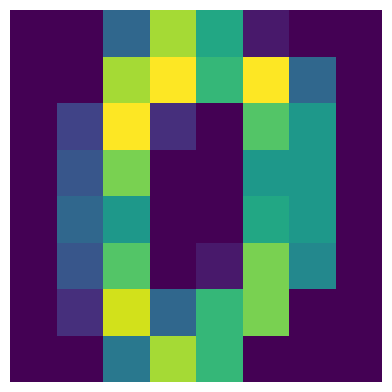

0


In [4]:
plt.matshow(digits.images[0])
plt.axis('off')
plt.show()

print(digits.target[0])

## PREPARING INPUTS AS FLATTENED IMAGES

### images are taken into 1D and used as features, digits is 8x8 so we have 64 features

In [5]:
print("Shape of images = ", digits.images.shape)
print("Shape of flattened images = ", digits.data.shape)

Shape of images =  (1797, 8, 8)
Shape of flattened images =  (1797, 64)


## GENERATE ONE DATA SPLIT OF TRAINING AND TEST

In [6]:
from sklearn.model_selection import train_test_split

# Define X and y
X = digits.data
y = digits.target

# Split X and y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

## TRAIN A BASELINE MODEL (NO REGULARIZATION, NO K-FOLD ETC)

In [9]:
# Class to display loss curves
class LossCurve(object):
  """Make sure the model verbose is set to 1"""
  def __enter__(self):
    self.old_stdout = sys.stdout
    sys.stdout = self.mystdout = io.StringIO()

  def __exit__(self, *args, **kwargs):
    sys.stdout = self.old_stdout
    loss_history = self.mystdout.getvalue()
    loss_list = []
    for line in loss_history.split('\n'):
      if(len(line.split("loss: ")) == 1):
        continue
      loss_str = line.split("loss: ")[-1].split(",")[0].strip()
      loss_list.append(float(loss_str))

    plt.figure()
    plt.plot(np.arange(len(loss_list)), loss_list)
    plt.xlabel("Iterations")
    plt.ylabel("Loss")

    return True

[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.1s finished


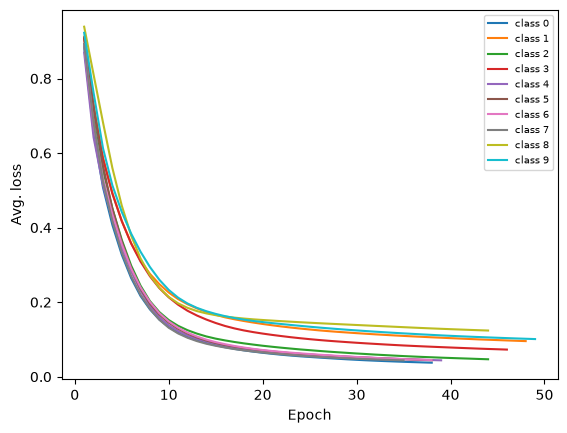

In [14]:
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create standardization scaler instance
std_scaler = StandardScaler()

# Create model instance
model = SGDClassifier(loss='hinge', penalty=None, eta0=0.0001, learning_rate='constant', verbose=1)

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Fit the model on training set
with LossCurve():
    clf.fit(X_train, y_train)

In [13]:
# Class to display loss curves
class LossCurve(object):
  """Make sure the model verbose is set to 1"""
  def __enter__(self):
    self.old_stdout = sys.stdout
    sys.stdout = self.mystdout = io.StringIO()

  def __exit__(self, *args, **kwargs):
    sys.stdout = self.old_stdout
    runs = []
    for line in self.mystdout.getvalue().split('\n'):
      if line.strip() == "-- Epoch 1":
        runs.append([])          # a new one-vs-rest classifier starts
      if "loss: " in line:
        if not runs:
          runs.append([])
        runs[-1].append(float(line.split("loss: ")[-1].split(",")[0]))
    plt.figure()
    for i, losses in enumerate(runs):
      plt.plot(np.arange(1, len(losses) + 1), losses, label=f"class {i}")
    plt.xlabel("Epoch")
    plt.ylabel("Avg. loss")
    plt.legend(fontsize=7)
    return False   # let exceptions from fit() show up


## ADD K-FOLD VALIDATION AND SEE THE SCORES ACROSS ALL SPLITS. IS THE MODEL BIASED?

In [15]:
from sklearn.model_selection import cross_val_score

# Create model instance
model = SGDClassifier(loss='hinge', eta0=0.0001, learning_rate='constant', penalty=None)

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Calculate cross-validation accuracy for 5 fold CV
scores = cross_val_score(clf, X, y, cv=5)

print("Scores = ", scores)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

Scores =  [0.93611111 0.86388889 0.90250696 0.93036212 0.86629526]
0.90 accuracy with a standard deviation of 0.03


## ADD SOME REGULARIZATION, EVALUATE

## L1 Regularization

In [46]:
# L1 Reg with lambda = 0.00001
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l1', alpha=0.00001, eta0=0.0001, learning_rate='constant')

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Calculate cross-validation accuracy for 5 fold CV
scores = cross_val_score(clf, X, y, cv=5)

print("Scores = ", scores)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

Scores =  [0.93333333 0.86388889 0.90250696 0.93314763 0.86629526]
0.90 accuracy with a standard deviation of 0.03


In [45]:
# L1 Reg with lambda = 0.1
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l1', alpha=0.1, eta0=0.0001, learning_rate='constant')

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Calculate cross-validation accuracy for 5 fold CV
scores = cross_val_score(clf, X, y, cv=5)

print("Scores = ", scores)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

Scores =  [0.43611111 0.55833333 0.57103064 0.53481894 0.56824513]
0.53 accuracy with a standard deviation of 0.05


In [44]:
# L1 Reg with lambda = 0.1
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l1', alpha=0.01, eta0=0.0001, learning_rate='constant')

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Calculate cross-validation accuracy for 5 fold CV
scores = cross_val_score(clf, X, y, cv=5)

print("Scores = ", scores)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

Scores =  [0.925      0.85277778 0.88579387 0.91922006 0.84958217]
0.89 accuracy with a standard deviation of 0.03


## L2 Regularization

In [47]:
# L2 Reg with lambda = 0.001
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l2', alpha=0.001, eta0=0.0001, learning_rate='constant')

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Calculate cross-validation accuracy for 5 fold CV
scores = cross_val_score(clf, X, y, cv=5)

print("Scores = ", scores)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

Scores =  [0.93611111 0.86388889 0.90250696 0.93036212 0.86629526]
0.90 accuracy with a standard deviation of 0.03


In [48]:
# L2 Reg with lambda = 0.1
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l2', alpha=0.1, eta0=0.0001, learning_rate='constant')

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Calculate cross-validation accuracy for 5 fold CV
scores = cross_val_score(clf, X, y, cv=5)

print("Scores = ", scores)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

Scores =  [0.91666667 0.85555556 0.88022284 0.91922006 0.8551532 ]
0.89 accuracy with a standard deviation of 0.03


In [49]:
# L2 Reg with lambda = 100
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l2', alpha=100, eta0=0.0001, learning_rate='constant')

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Calculate cross-validation accuracy for 5 fold CV
scores = cross_val_score(clf, X, y, cv=5)

print("Scores = ", scores)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

Scores =  [0.79444444 0.76666667 0.77715877 0.80222841 0.71309192]
0.77 accuracy with a standard deviation of 0.03


## SGD WITH HINGE LOSS, USE SOME HYPERPARAMS LIKE:

LEARNING RATE SCHEDULER, INITIAL LEARNING RATE (ETA0), ITERATIONS,

## Initial learning rate

[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.1s finished


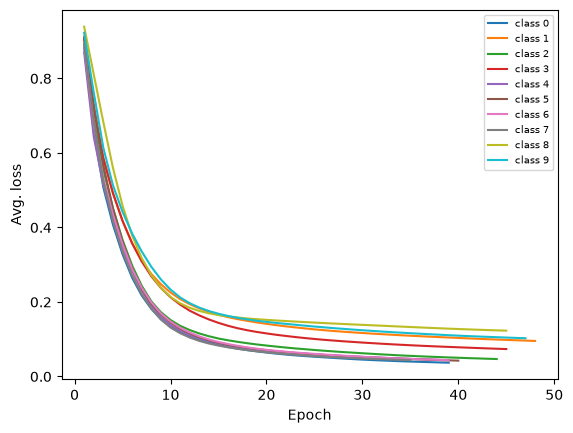

In [50]:
# LR = 0.0001
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l2', learning_rate='constant', eta0=0.0001, verbose=1)

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Fit the model on training set
with LossCurve():
    clf.fit(X_train, y_train)

[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.0s finished


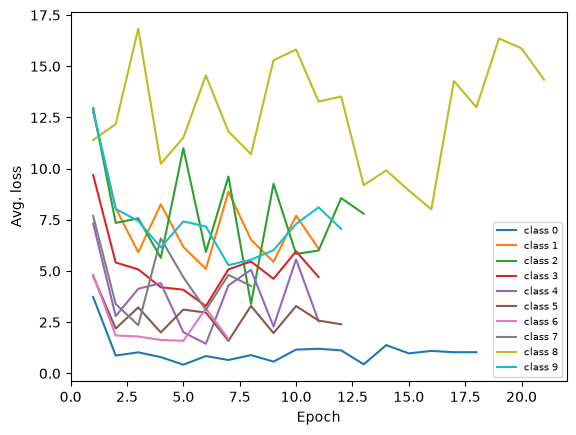

In [51]:
# LR = 10
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l2', learning_rate='constant', eta0=10, verbose=1)

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Fit the model on training set
with LossCurve():
    clf.fit(X_train, y_train)

In [59]:
# LR = 10
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l2', learning_rate='constant', eta0=10)

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Calculate cross-validation accuracy for 5 fold CV
scores = cross_val_score(clf, X, y, cv=5)

print("Scores = ", scores)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

Scores =  [0.82777778 0.81944444 0.87743733 0.89972145 0.8189415 ]
0.85 accuracy with a standard deviation of 0.03


In [58]:
# LR = 0.0001
# Create model instance
model = SGDClassifier(loss='hinge', penalty='l2', learning_rate='constant', eta0=0.0001)

# Make a pipeline of steps
clf = make_pipeline(std_scaler, model)

# Calculate cross-validation accuracy for 5 fold CV
scores = cross_val_score(clf, X, y, cv=5)

print("Scores = ", scores)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

Scores =  [0.93611111 0.86388889 0.90250696 0.93036212 0.86629526]
0.90 accuracy with a standard deviation of 0.03


# Grid Search CV

## First grid search

In [60]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Create model instance
model = SGDClassifier(loss='hinge', penalty='l2', learning_rate='constant')

# Make a pipeline of steps
clf = Pipeline(steps=[("std_scaler", std_scaler), ("model", model)])

param_grid = {'model__alpha': [0.00001, 0.0001, 0.001, 0.1, 1, 10, 100, 1000],
              'model__eta0': [100, 10, 1, 0.1, 0.01, 0.001, 0.0001, 0.00001]
              }

grid = GridSearchCV(clf, param_grid, refit = True, verbose = 3)

# Fit on train data
grid.fit(X_train, y_train)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
[CV 1/5] END model__alpha=1e-05, model__eta0=100;, score=0.892 total time=   0.0s
[CV 2/5] END model__alpha=1e-05, model__eta0=100;, score=0.872 total time=   0.0s
[CV 3/5] END model__alpha=1e-05, model__eta0=100;, score=0.878 total time=   0.0s
[CV 4/5] END model__alpha=1e-05, model__eta0=100;, score=0.868 total time=   0.0s
[CV 5/5] END model__alpha=1e-05, model__eta0=100;, score=0.882 total time=   0.0s
[CV 1/5] END model__alpha=1e-05, model__eta0=10;, score=0.931 total time=   0.0s
[CV 2/5] END model__alpha=1e-05, model__eta0=10;, score=0.931 total time=   0.0s
[CV 3/5] END model__alpha=1e-05, model__eta0=10;, score=0.948 total time=   0.0s
[CV 4/5] END model__alpha=1e-05, model__eta0=10;, score=0.934 total time=   0.0s
[CV 5/5] END model__alpha=1e-05, model__eta0=10;, score=0.948 total time=   0.0s
[CV 1/5] END .model__alpha=1e-05, model__eta0=1;, score=0.927 total time=   0.0s
[CV 2/5] END .model__alpha=1e-05, model__e

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'constant'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [1e-05, 0.0001, ...], 'model__eta0': [100, 10, ...]}"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allo

In [61]:
# Mean cross-validated score of the best estimator
print("Mean CV accuracy of the best set of parameters = ", grid.best_score_)
print("Best set of parameters = ", grid.best_params_)

# Evaluate on test data
print("Test set accuracy = ", grid.score(X_test, y_test))

Mean CV accuracy of the best set of parameters =  0.9568573364305071
Best set of parameters =  {'model__alpha': 0.0001, 'model__eta0': 0.01}
Test set accuracy =  0.9583333333333334


# Random Search CV

In [62]:
from sklearn.model_selection import RandomizedSearchCV

# Create model instance
model = SGDClassifier(loss='hinge', penalty='l2', learning_rate='constant')

# Make a pipeline of steps
clf = Pipeline(steps=[("std_scaler", std_scaler), ("model", model)])

param_grid = {'model__alpha': [0.00001, 0.0001, 0.001, 0.1, 1, 10, 100, 1000],
              'model__eta0': [100, 10, 1, 0.1, 0.01, 0.001, 0.0001, 0.00001]
              }

grid = RandomizedSearchCV(clf, param_grid, n_iter = 50, refit = True, verbose = 1)

# Fit on train data
grid.fit(X_train, y_train)

# Mean cross-validated score of the best estimator
print("Mean CV accuracy of the best set of parameters = ", grid.best_score_)
print("Best set of parameters = ", grid.best_params_)

# Evaluate on test data
print("Test set accuracy = ", grid.score(X_test, y_test))

Fitting 5 folds for each of 50 candidates, totalling 250 fits


Mean CV accuracy of the best set of parameters =  0.9589406697638406
Best set of parameters =  {'model__eta0': 0.01, 'model__alpha': 0.001}
Test set accuracy =  0.9333333333333333
